### Coping Mechanism Recommendation (Supervised Learning)
#
#### Objective
##### Build a classification model to predict the **effectiveness of coping strategies** (0 = not effective, 1 = somewhat, 2 = very effective) based on student profiles, stress context, and social factors. The trained model is then used to recommend the most effective coping strategy for each student.
#
#### Why Supervised Learning?
##### Students have already reported which coping strategies they used and how effective they were. This labeled data allows us to learn which strategies work best for different student profiles and recommend accordingly.

#### Section 1: Install and Import Libraries

In [1]:
# ============================================================
# SECTION 1: INSTALL AND IMPORT LIBRARIES
# ============================================================
# !pip install pandas numpy scikit-learn matplotlib seaborn xgboost lightgbm

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, cohen_kappa_score, matthews_corrcoef)
import warnings
warnings.filterwarnings('ignore')

try:
    import xgboost as xgb; HAS_XGB = True; print("[OK] XGBoost loaded")
except: HAS_XGB = False; print("[WARN] XGBoost not installed")

try:
    import lightgbm as lgb; HAS_LGB = True; print("[OK] LightGBM loaded")
except: HAS_LGB = False; print("[WARN] LightGBM not installed")

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("\n" + "=" * 60)
print("COPING MECHANISM RECOMMENDATION")
print("=" * 60)

[OK] XGBoost loaded
[OK] LightGBM loaded

COPING MECHANISM RECOMMENDATION


#### Section 2: Load and Inspect Data

In [2]:
# ============================================================
# SECTION 2: LOAD AND INSPECT DATA
# ============================================================
df = pd.read_csv('c3_intervention_dataset.csv')

print(f"Dataset shape: {df.shape}")
print(f"Students: {df['student_id'].nunique()}")
print(f"Weeks: {sorted(df['week'].unique())}")
print(f"\nColumn types:\n{df.dtypes}")
print(f"\nFirst 5 rows:")
df.head()

# %%
# Display target distribution
print("\n--- Target Variable: coping_effectiveness ---")
eff_dist = df['coping_effectiveness'].value_counts().sort_index()
labels = {0: 'Not effective', 1: 'Somewhat effective', 2: 'Very effective'}
for val, count in eff_dist.items():
    pct = count / len(df) * 100
    print(f"  {val} ({labels[val]}): {count} ({pct:.1f}%)")


Dataset shape: (1010, 18)
Students: 200
Weeks: [np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12)]

Column types:
student_id                 object
week                        int64
stress_trigger             object
coping_strategies_used     object
coping_primary_strategy    object
coping_effectiveness        int64
break_frequency             int64
talks_to_someone            int64
belonging_score             int64
loneliness_score            int64
help_seeking_comfort        int64
group_inclusion             int64
has_support_person          int64
class_support               int64
class_competition           int64
peer_helping                int64
strategy_feedback           int64
peer_support_feedback       int64
dtype: object

First 5 rows:

--- Target Variable: coping_effectiveness ---
  0 (Not effective): 159 (15.7%)
  1 (Somewhat effective): 345 (34.2%)
  2 (Very effective): 506 (50.1%)


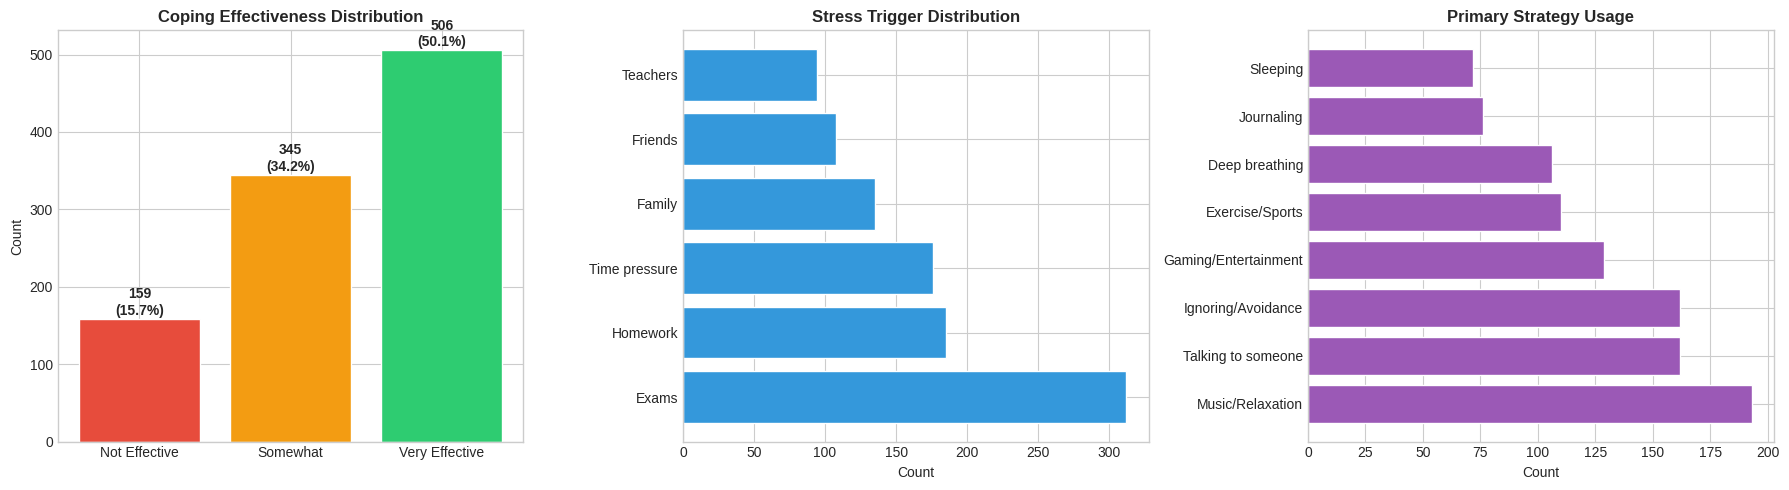

In [3]:
# ============================================================
# EDA CHART 1: COPING EFFECTIVENESS DISTRIBUTION
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Target distribution
colors_eff = ['#e74c3c', '#f39c12', '#2ecc71']
bars = axes[0].bar(eff_dist.index, eff_dist.values, color=colors_eff, edgecolor='white')
for bar, (val, cnt) in zip(bars, eff_dist.items()):
    pct = cnt / len(df) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{cnt}\n({pct:.1f}%)', ha='center', fontweight='bold')
axes[0].set_title('Coping Effectiveness Distribution', fontweight='bold')
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(['Not Effective', 'Somewhat', 'Very Effective'])
axes[0].set_ylabel('Count')

# Stress triggers
trigger_counts = df['stress_trigger'].value_counts()
axes[1].barh(trigger_counts.index, trigger_counts.values, color='#3498db', edgecolor='white')
axes[1].set_title('Stress Trigger Distribution', fontweight='bold')
axes[1].set_xlabel('Count')

# Primary strategy usage
strat_counts = df['coping_primary_strategy'].value_counts()
axes[2].barh(strat_counts.index, strat_counts.values, color='#9b59b6', edgecolor='white')
axes[2].set_title('Primary Strategy Usage', fontweight='bold')
axes[2].set_xlabel('Count')

plt.tight_layout()
plt.savefig('c5_chart1_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

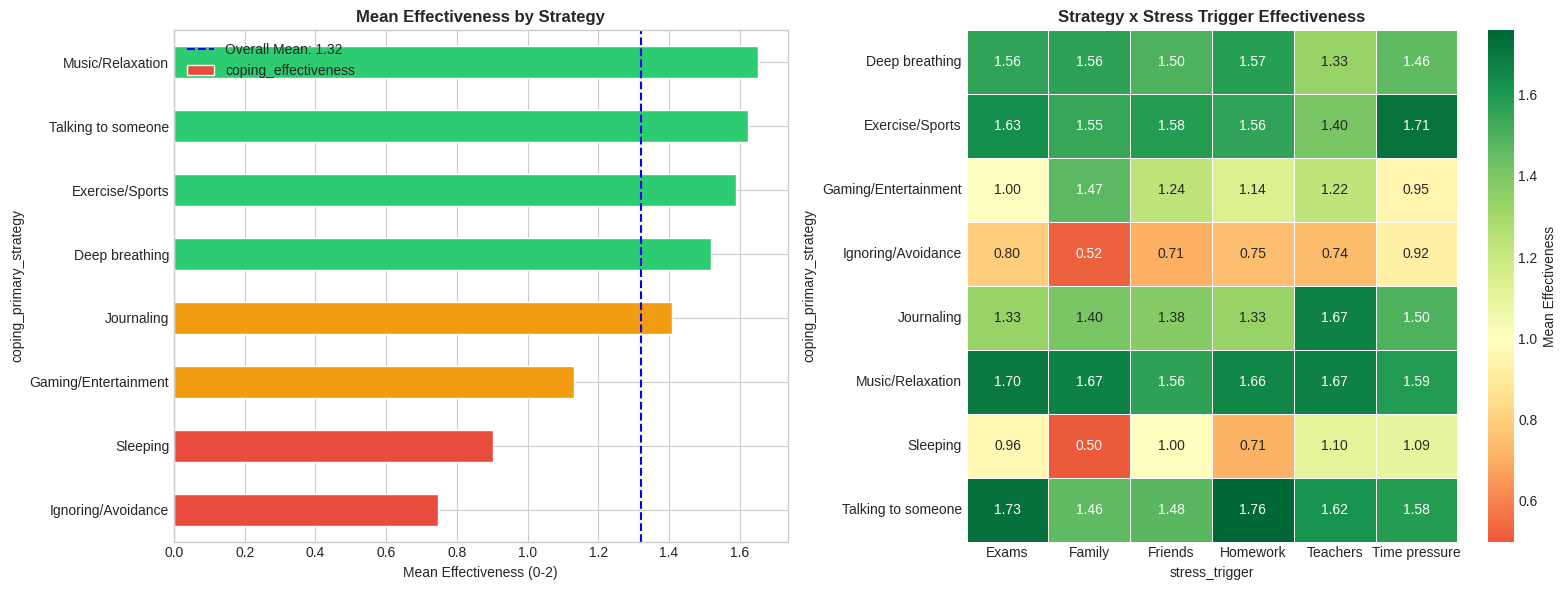

In [4]:
# ============================================================
# EDA CHART 2: STRATEGY EFFECTIVENESS ANALYSIS
# ============================================================
# The core insight: Which strategies actually WORK?
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Mean effectiveness per strategy
strat_eff = df.groupby('coping_primary_strategy')['coping_effectiveness'].mean().sort_values(ascending=True)
colors_strat = ['#e74c3c' if v < 1.0 else '#f39c12' if v < 1.5 else '#2ecc71' for v in strat_eff.values]
strat_eff.plot(kind='barh', ax=axes[0], color=colors_strat, edgecolor='white')
axes[0].set_title('Mean Effectiveness by Strategy', fontweight='bold')
axes[0].set_xlabel('Mean Effectiveness (0-2)')
axes[0].axvline(strat_eff.mean(), color='blue', linestyle='--', label=f'Overall Mean: {strat_eff.mean():.2f}')
axes[0].legend()

# Strategy x Trigger heatmap
pivot = df.pivot_table(values='coping_effectiveness', index='coping_primary_strategy',
                       columns='stress_trigger', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn', ax=axes[1], center=1.0,
            linewidths=0.5, cbar_kws={'label': 'Mean Effectiveness'})
axes[1].set_title('Strategy x Stress Trigger Effectiveness', fontweight='bold')

plt.tight_layout()
plt.savefig('c5_chart2_strategy_effectiveness.png', dpi=150, bbox_inches='tight')
plt.show()

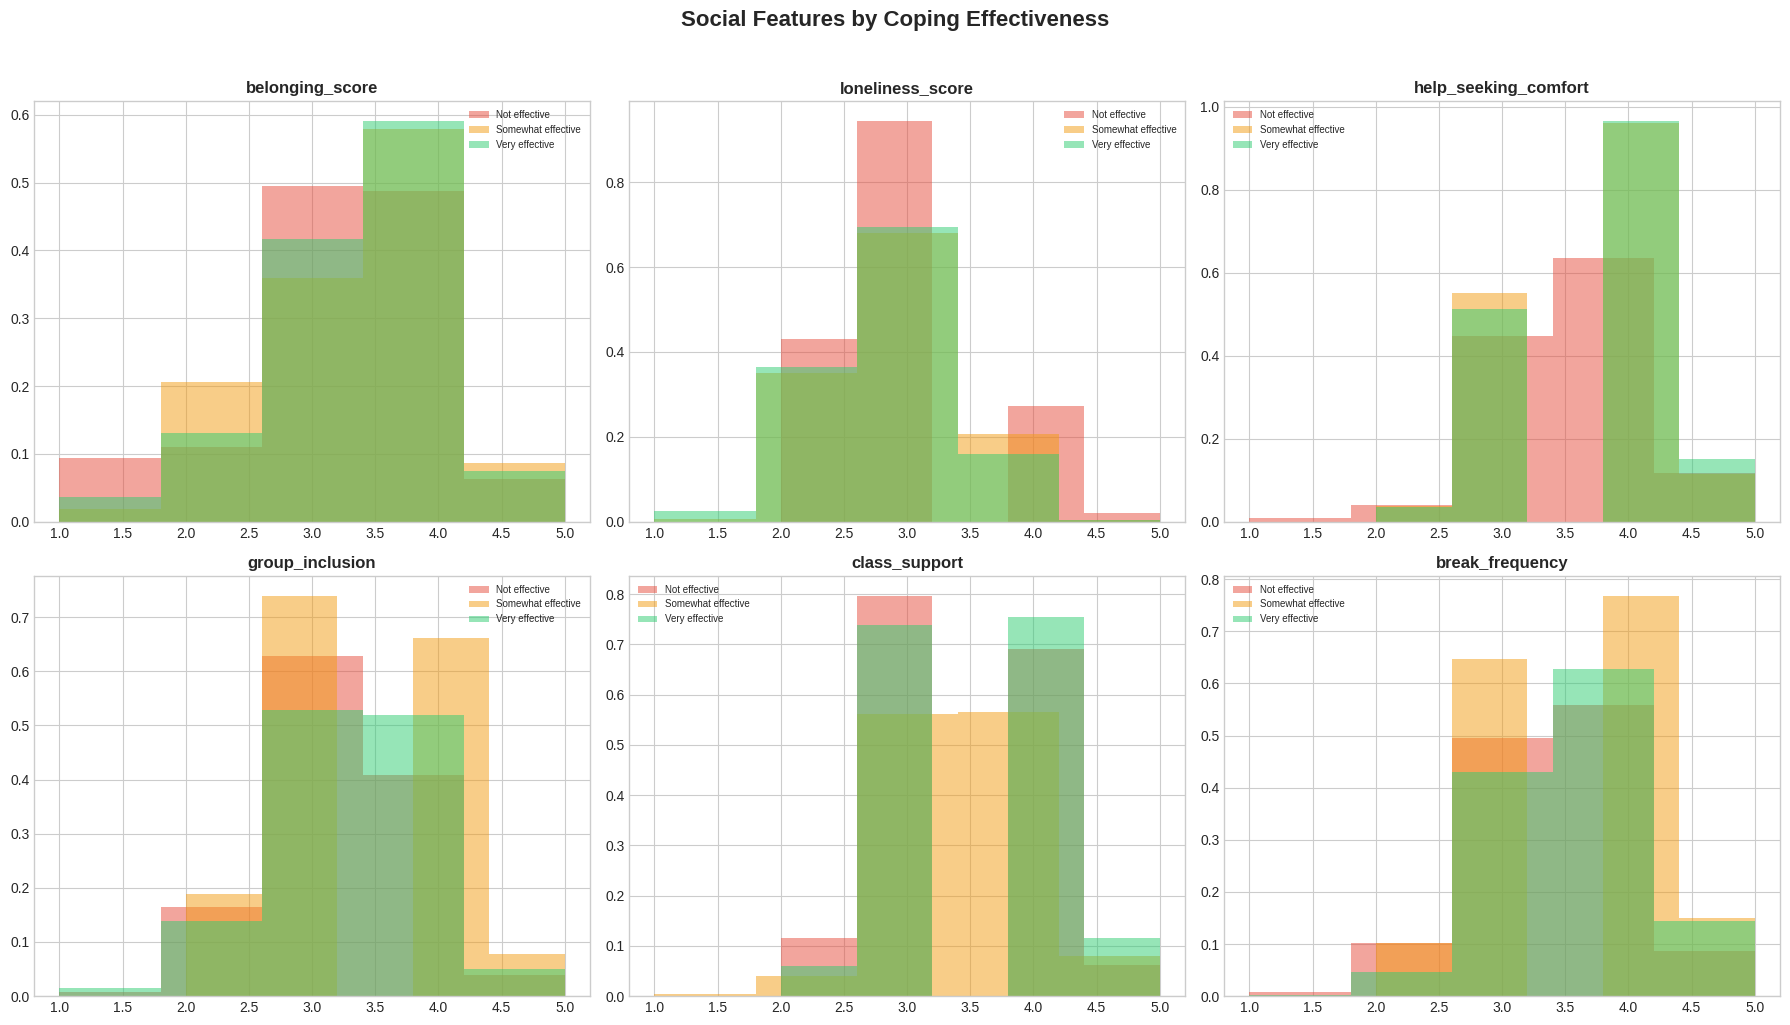

In [5]:
# ============================================================
# EDA CHART 3: SOCIAL FACTORS vs COPING
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

social_features = ['belonging_score', 'loneliness_score', 'help_seeking_comfort',
                   'group_inclusion', 'class_support', 'break_frequency']

for i, feat in enumerate(social_features):
    for eff_val in [0, 1, 2]:
        data = df[df['coping_effectiveness'] == eff_val][feat]
        axes[i].hist(data, bins=5, alpha=0.5, color=colors_eff[eff_val],
                     label=labels[eff_val], density=True)
    axes[i].set_title(f'{feat}', fontweight='bold')
    axes[i].legend(fontsize=7)

fig.suptitle('Social Features by Coping Effectiveness', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('c5_chart3_social_vs_coping.png', dpi=150, bbox_inches='tight')
plt.show()

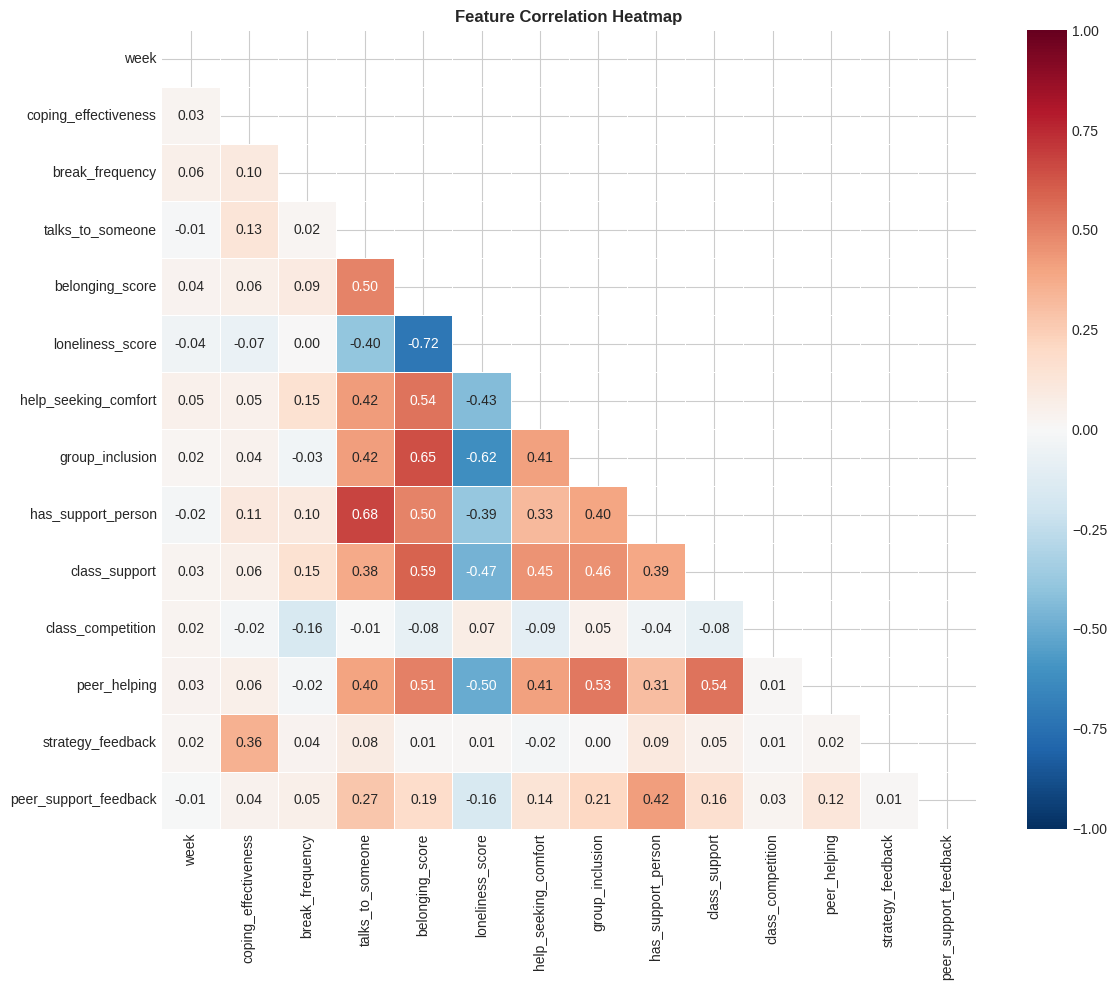


--- Correlations with coping_effectiveness ---
  strategy_feedback: 0.355
  talks_to_someone: 0.128
  has_support_person: 0.105
  break_frequency: 0.101
  class_support: 0.060
  belonging_score: 0.060
  peer_helping: 0.055
  help_seeking_comfort: 0.049
  peer_support_feedback: 0.043
  group_inclusion: 0.040
  week: 0.031
  class_competition: -0.018
  loneliness_score: -0.070


In [6]:
# ============================================================
# EDA CHART 4: CORRELATION HEATMAP
# ============================================================
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, linewidths=0.5, vmin=-1, vmax=1)
ax.set_title('Feature Correlation Heatmap', fontweight='bold')
plt.tight_layout()
plt.savefig('c5_chart4_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

# Show correlations with target
print("\n--- Correlations with coping_effectiveness ---")
target_corr = corr['coping_effectiveness'].drop('coping_effectiveness').sort_values(ascending=False)
for feat, val in target_corr.items():
    print(f"  {feat}: {val:.3f}")

#### Section 3: Feature Engineering

In [7]:
# ============================================================
# SECTION 3: FEATURE ENGINEERING
# ============================================================
print("\n" + "=" * 60)
print("SECTION 3: FEATURE ENGINEERING")
print("=" * 60)

# --- Feature 1: MultiLabelBinarizer on coping_strategies_used ---
# Convert pipe-separated strategy lists into binary columns
df['strategy_list'] = df['coping_strategies_used'].apply(lambda x: x.split('|'))
mlb = MultiLabelBinarizer()
strategy_binary = pd.DataFrame(
    mlb.fit_transform(df['strategy_list']),
    columns=[f'uses_{s.lower().replace("/", "_").replace(" ", "_")}' for s in mlb.classes_],
    index=df.index
)
df = pd.concat([df, strategy_binary], axis=1)
print(f"[+] MultiLabelBinarizer: {len(mlb.classes_)} strategy columns created")

# --- Feature 2: One-Hot Encode stress_trigger ---
trigger_dummies = pd.get_dummies(df['stress_trigger'], prefix='trigger')
df = pd.concat([df, trigger_dummies], axis=1)
print(f"[+] One-Hot stress_trigger: {len(trigger_dummies.columns)} columns")

# --- Feature 3: One-Hot Encode primary strategy ---
primary_dummies = pd.get_dummies(df['coping_primary_strategy'], prefix='primary')
df = pd.concat([df, primary_dummies], axis=1)
print(f"[+] One-Hot primary_strategy: {len(primary_dummies.columns)} columns")

# --- Feature 4: Social Support Score ---
df['social_support_score'] = (df['belonging_score'] + df['group_inclusion'] + df['help_seeking_comfort']) / 3
print(f"[+] social_support_score (mean: {df['social_support_score'].mean():.2f})")

# --- Feature 5: Isolation Risk ---
df['isolation_risk'] = df['loneliness_score'] - df['belonging_score']
print(f"[+] isolation_risk (mean: {df['isolation_risk'].mean():.2f})")

# --- Feature 6: Coping Diversity ---
df['coping_diversity'] = df['strategy_list'].apply(len)
print(f"[+] coping_diversity (mean: {df['coping_diversity'].mean():.2f})")

# --- Feature 7: Support Network Strength ---
df['support_network_strength'] = df['has_support_person'] + df['talks_to_someone'] + df['peer_helping'] / 5
print(f"[+] support_network_strength (mean: {df['support_network_strength'].mean():.2f})")

# --- Feature 8: Class Climate Score ---
df['class_climate_score'] = df['class_support'] - df['class_competition']
print(f"[+] class_climate_score (mean: {df['class_climate_score'].mean():.2f})")

# --- Feature 9: Strategy is Active ---
active_strategies = ['Exercise/Sports', 'Talking to someone', 'Deep breathing']
df['strategy_is_active'] = df['coping_primary_strategy'].isin(active_strategies).astype(int)
print(f"[+] strategy_is_active (mean: {df['strategy_is_active'].mean():.2f})")

# --- Feature 10: Strategy is Avoidant ---
avoidant_strategies = ['Ignoring/Avoidance', 'Sleeping', 'Gaming/Entertainment']
df['strategy_is_avoidant'] = df['coping_primary_strategy'].isin(avoidant_strategies).astype(int)
print(f"[+] strategy_is_avoidant (mean: {df['strategy_is_avoidant'].mean():.2f})")

print(f"\nTotal columns after engineering: {len(df.columns)}")


SECTION 3: FEATURE ENGINEERING
[+] MultiLabelBinarizer: 8 strategy columns created
[+] One-Hot stress_trigger: 6 columns
[+] One-Hot primary_strategy: 8 columns
[+] social_support_score (mean: 3.48)
[+] isolation_risk (mean: -0.54)
[+] coping_diversity (mean: 2.00)
[+] support_network_strength (mean: 2.42)
[+] class_climate_score (mean: 0.23)
[+] strategy_is_active (mean: 0.37)
[+] strategy_is_avoidant (mean: 0.36)

Total columns after engineering: 48


####Section 4: Prepare Feature & Split

In [8]:
# ============================================================
# SECTION 4: PREPARE FEATURES & SPLIT
# ============================================================
print("\n" + "=" * 60)
print("SECTION 4: PREPARE FEATURES & SPLIT")
print("=" * 60)

# Drop non-feature columns
drop_cols = ['student_id', 'coping_strategies_used', 'coping_primary_strategy',
             'stress_trigger', 'strategy_list', 'coping_effectiveness',
             'strategy_feedback', 'peer_support_feedback']

feature_cols = [c for c in df.columns if c not in drop_cols]
X = df[feature_cols].copy()
y = df['coping_effectiveness'].copy()

print(f"Features: {X.shape[1]}")
print(f"Samples: {X.shape[0]}")
print(f"\nClass distribution:")
print(y.value_counts().sort_index())

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTrain: {X_train.shape[0]} | Test: {X_test.shape[0]}")

print("\n" + "=" * 60)
print("PART 1 COMPLETE: EDA & Feature Engineering done!")
print("Proceed to Part 2 for Model Training.")
print("=" * 60)



SECTION 4: PREPARE FEATURES & SPLIT
Features: 40
Samples: 1010

Class distribution:
coping_effectiveness
0    159
1    345
2    506
Name: count, dtype: int64

Train: 808 | Test: 202

PART 1 COMPLETE: EDA & Feature Engineering done!
Proceed to Part 2 for Model Training.


#### Section 5: Model Training

In [9]:
# ============================================================
# SETUP (Run after Part 1 or standalone)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, cohen_kappa_score, matthews_corrcoef)
import joblib
import warnings
warnings.filterwarnings('ignore')

try:
    import xgboost as xgb; HAS_XGB = True
except: HAS_XGB = False
try:
    import lightgbm as lgb; HAS_LGB = True
except: HAS_LGB = False

plt.style.use('seaborn-v0_8-whitegrid')

# --- Recreate full pipeline ---
df = pd.read_csv('c3_intervention_dataset.csv')
df['strategy_list'] = df['coping_strategies_used'].apply(lambda x: x.split('|'))
mlb = MultiLabelBinarizer()
strat_bin = pd.DataFrame(mlb.fit_transform(df['strategy_list']),
    columns=[f'uses_{s.lower().replace("/","_").replace(" ","_")}' for s in mlb.classes_], index=df.index)
df = pd.concat([df, strat_bin], axis=1)
df = pd.concat([df, pd.get_dummies(df['stress_trigger'], prefix='trigger')], axis=1)
df = pd.concat([df, pd.get_dummies(df['coping_primary_strategy'], prefix='primary')], axis=1)

df['social_support_score'] = (df['belonging_score'] + df['group_inclusion'] + df['help_seeking_comfort']) / 3
df['isolation_risk'] = df['loneliness_score'] - df['belonging_score']
df['coping_diversity'] = df['strategy_list'].apply(len)
df['support_network_strength'] = df['has_support_person'] + df['talks_to_someone'] + df['peer_helping'] / 5
df['class_climate_score'] = df['class_support'] - df['class_competition']
active = ['Exercise/Sports', 'Talking to someone', 'Deep breathing']
avoidant = ['Ignoring/Avoidance', 'Sleeping', 'Gaming/Entertainment']
df['strategy_is_active'] = df['coping_primary_strategy'].isin(active).astype(int)
df['strategy_is_avoidant'] = df['coping_primary_strategy'].isin(avoidant).astype(int)

drop_cols = ['student_id', 'coping_strategies_used', 'coping_primary_strategy',
             'stress_trigger', 'strategy_list', 'coping_effectiveness',
             'strategy_feedback', 'peer_support_feedback']
X = df[[c for c in df.columns if c not in drop_cols]]
y = df['coping_effectiveness']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

all_results = {}
all_models = {}
all_predictions = {}
class_names = ['Not Effective', 'Somewhat', 'Very Effective']
colors_bar = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

print("=" * 60)
print("SECTION 5: MODEL TRAINING")
print("=" * 60)


SECTION 5: MODEL TRAINING


In [10]:
# ============================================================
# MODEL 1: RANDOM FOREST
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 1: RANDOM FOREST")
print("#" * 50)

rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced']
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42), rf_params,
    n_iter=20, cv=StratifiedKFold(5), scoring='f1_macro', n_jobs=-1, random_state=42
)
rf_search.fit(X_train, y_train)
y_pred_rf = rf_search.predict(X_test)
print(f"Best params: {rf_search.best_params_}")
print(f"\n{classification_report(y_test, y_pred_rf, target_names=class_names)}")

all_results['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'F1_Macro': f1_score(y_test, y_pred_rf, average='macro'),
    'F1_Weighted': f1_score(y_test, y_pred_rf, average='weighted'),
    'Kappa': cohen_kappa_score(y_test, y_pred_rf),
    'MCC': matthews_corrcoef(y_test, y_pred_rf)
}
all_models['Random Forest'] = rf_search.best_estimator_
all_predictions['Random Forest'] = y_pred_rf


##################################################
# MODEL 1: RANDOM FOREST
##################################################
Best params: {'n_estimators': 200, 'min_samples_split': 10, 'max_depth': None, 'class_weight': 'balanced'}

                precision    recall  f1-score   support

 Not Effective       0.33      0.53      0.40        32
      Somewhat       0.47      0.28      0.35        69
Very Effective       0.65      0.71      0.68       101

      accuracy                           0.53       202
     macro avg       0.49      0.51      0.48       202
  weighted avg       0.54      0.53      0.52       202



In [11]:
# ============================================================
# MODEL 2: XGBOOST
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 2: XGBOOST")
print("#" * 50)

if HAS_XGB:
    xgb_params = {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.8, 1.0]
    }
    xgb_search = RandomizedSearchCV(
        xgb.XGBClassifier(random_state=42, eval_metric='mlogloss', use_label_encoder=False),
        xgb_params, n_iter=20, cv=StratifiedKFold(5), scoring='f1_macro', n_jobs=-1, random_state=42
    )
    xgb_search.fit(X_train, y_train)
    y_pred_xgb = xgb_search.predict(X_test)
    print(f"Best params: {xgb_search.best_params_}")
    print(f"\n{classification_report(y_test, y_pred_xgb, target_names=class_names)}")
    all_results['XGBoost'] = {
        'Accuracy': accuracy_score(y_test, y_pred_xgb),
        'F1_Macro': f1_score(y_test, y_pred_xgb, average='macro'),
        'F1_Weighted': f1_score(y_test, y_pred_xgb, average='weighted'),
        'Kappa': cohen_kappa_score(y_test, y_pred_xgb),
        'MCC': matthews_corrcoef(y_test, y_pred_xgb)
    }
    all_models['XGBoost'] = xgb_search.best_estimator_
    all_predictions['XGBoost'] = y_pred_xgb
else:
    print("[SKIP] XGBoost not installed")


##################################################
# MODEL 2: XGBOOST
##################################################
Best params: {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.1}

                precision    recall  f1-score   support

 Not Effective       0.33      0.34      0.34        32
      Somewhat       0.30      0.19      0.23        69
Very Effective       0.60      0.75      0.67       101

      accuracy                           0.50       202
     macro avg       0.41      0.43      0.41       202
  weighted avg       0.46      0.50      0.47       202



In [12]:
# ============================================================
# MODEL 3: LIGHTGBM
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 3: LIGHTGBM")
print("#" * 50)

if HAS_LGB:
    lgb_params = {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.05, 0.1],
        'num_leaves': [15, 31, 63]
    }
    lgb_search = RandomizedSearchCV(
        lgb.LGBMClassifier(random_state=42, verbose=-1),
        lgb_params, n_iter=20, cv=StratifiedKFold(5), scoring='f1_macro', n_jobs=-1, random_state=42
    )
    lgb_search.fit(X_train, y_train)
    y_pred_lgb = lgb_search.predict(X_test)
    print(f"Best params: {lgb_search.best_params_}")
    print(f"\n{classification_report(y_test, y_pred_lgb, target_names=class_names)}")
    all_results['LightGBM'] = {
        'Accuracy': accuracy_score(y_test, y_pred_lgb),
        'F1_Macro': f1_score(y_test, y_pred_lgb, average='macro'),
        'F1_Weighted': f1_score(y_test, y_pred_lgb, average='weighted'),
        'Kappa': cohen_kappa_score(y_test, y_pred_lgb),
        'MCC': matthews_corrcoef(y_test, y_pred_lgb)
    }
    all_models['LightGBM'] = lgb_search.best_estimator_
    all_predictions['LightGBM'] = y_pred_lgb
else:
    print("[SKIP] LightGBM not installed")


##################################################
# MODEL 3: LIGHTGBM
##################################################
Best params: {'num_leaves': 31, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.1}

                precision    recall  f1-score   support

 Not Effective       0.41      0.41      0.41        32
      Somewhat       0.31      0.22      0.26        69
Very Effective       0.58      0.70      0.64       101

      accuracy                           0.49       202
     macro avg       0.43      0.44      0.43       202
  weighted avg       0.46      0.49      0.47       202



In [13]:
# ============================================================
# MODEL 4: SVM (RBF Kernel)
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 4: SVM (RBF Kernel)")
print("#" * 50)

# Scale for SVM
scaler = StandardScaler()
X_train_svm = scaler.fit_transform(X_train)
X_test_svm = scaler.transform(X_test)

svm_params = {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto']}
svm_search = RandomizedSearchCV(
    SVC(kernel='rbf', random_state=42, class_weight='balanced'),
    svm_params, n_iter=6, cv=StratifiedKFold(5), scoring='f1_macro', n_jobs=-1, random_state=42
)
svm_search.fit(X_train_svm, y_train)
y_pred_svm = svm_search.predict(X_test_svm)
print(f"Best params: {svm_search.best_params_}")
print(f"\n{classification_report(y_test, y_pred_svm, target_names=class_names)}")
all_results['SVM'] = {
    'Accuracy': accuracy_score(y_test, y_pred_svm),
    'F1_Macro': f1_score(y_test, y_pred_svm, average='macro'),
    'F1_Weighted': f1_score(y_test, y_pred_svm, average='weighted'),
    'Kappa': cohen_kappa_score(y_test, y_pred_svm),
    'MCC': matthews_corrcoef(y_test, y_pred_svm)
}
all_models['SVM'] = svm_search.best_estimator_
all_predictions['SVM'] = y_pred_svm


##################################################
# MODEL 4: SVM (RBF Kernel)
##################################################
Best params: {'gamma': 'scale', 'C': 1}

                precision    recall  f1-score   support

 Not Effective       0.35      0.75      0.48        32
      Somewhat       0.49      0.29      0.36        69
Very Effective       0.69      0.63      0.66       101

      accuracy                           0.53       202
     macro avg       0.51      0.56      0.50       202
  weighted avg       0.57      0.53      0.53       202



#### Section 6: Evaluation & Visualization

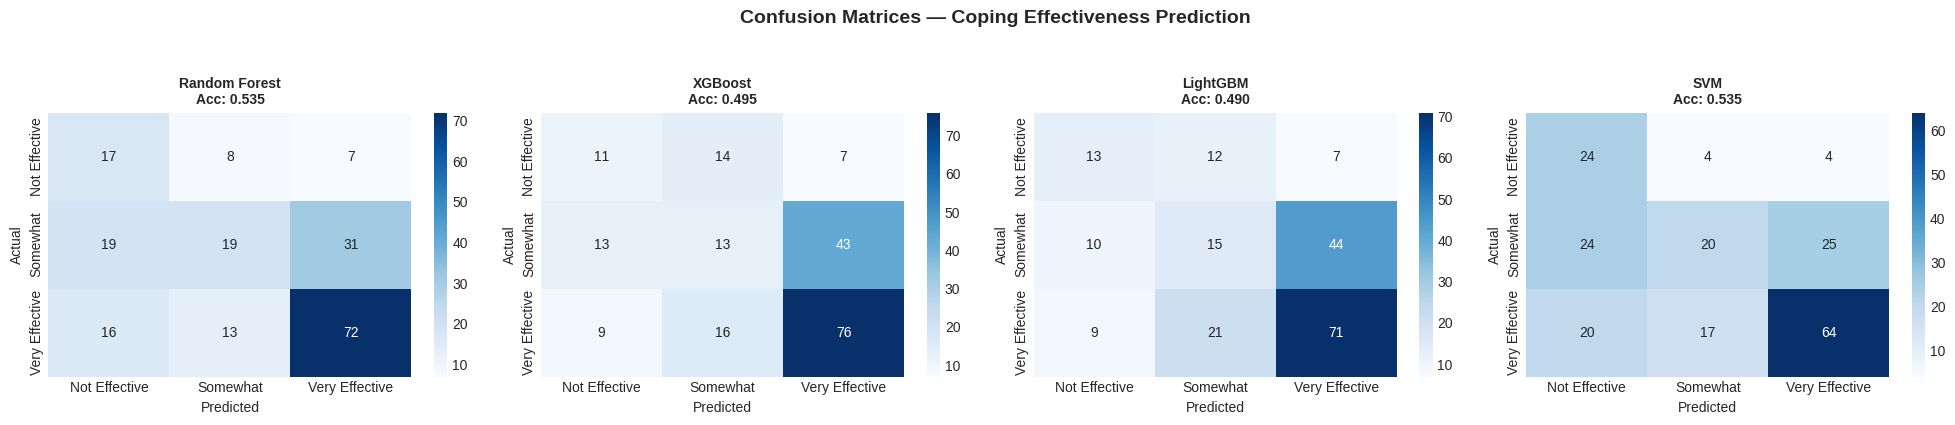

In [14]:
# ============================================================
# EVAL CHART 1: CONFUSION MATRICES
# ============================================================
n_models = len(all_predictions)
fig, axes = plt.subplots(1, n_models, figsize=(5 * n_models, 4))
if n_models == 1: axes = [axes]

for i, (name, y_pred) in enumerate(all_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=class_names, yticklabels=class_names)
    axes[i].set_title(f'{name}\nAcc: {all_results[name]["Accuracy"]:.3f}', fontweight='bold', fontsize=10)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

fig.suptitle('Confusion Matrices — Coping Effectiveness Prediction', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('c5_chart5_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()


MODEL COMPARISON TABLE
               Accuracy  F1_Macro  F1_Weighted   Kappa     MCC
Random Forest    0.5347    0.4786       0.5244  0.2486  0.2553
XGBoost          0.4950    0.4134       0.4677  0.1435  0.1477
LightGBM         0.4901    0.4331       0.4703  0.1383  0.1411
SVM              0.5347    0.5011       0.5301  0.2809  0.2929


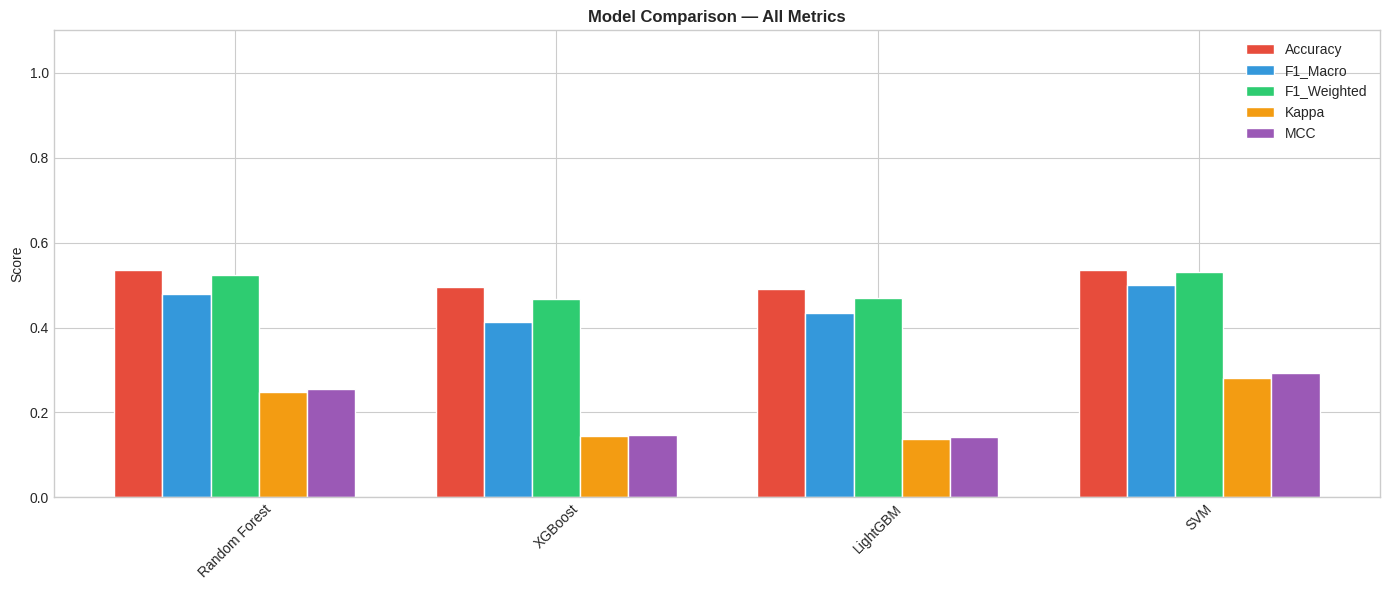

In [15]:
# ============================================================
# EVAL CHART 2: MODEL COMPARISON
# ============================================================
results_df = pd.DataFrame(all_results).T
print("\n" + "=" * 70)
print("MODEL COMPARISON TABLE")
print("=" * 70)
print(results_df.round(4).to_string())

fig, ax = plt.subplots(figsize=(14, 6))
metrics_plot = ['Accuracy', 'F1_Macro', 'F1_Weighted', 'Kappa', 'MCC']
x = np.arange(len(all_results))
width = 0.15
m_colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']

for i, metric in enumerate(metrics_plot):
    vals = [all_results[m][metric] for m in all_results]
    ax.bar(x + i * width, vals, width, label=metric, color=m_colors[i], edgecolor='white')

ax.set_xticks(x + width * 2)
ax.set_xticklabels(list(all_results.keys()), rotation=45)
ax.set_title('Model Comparison — All Metrics', fontweight='bold')
ax.set_ylabel('Score')
ax.legend()
ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.savefig('c5_chart6_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

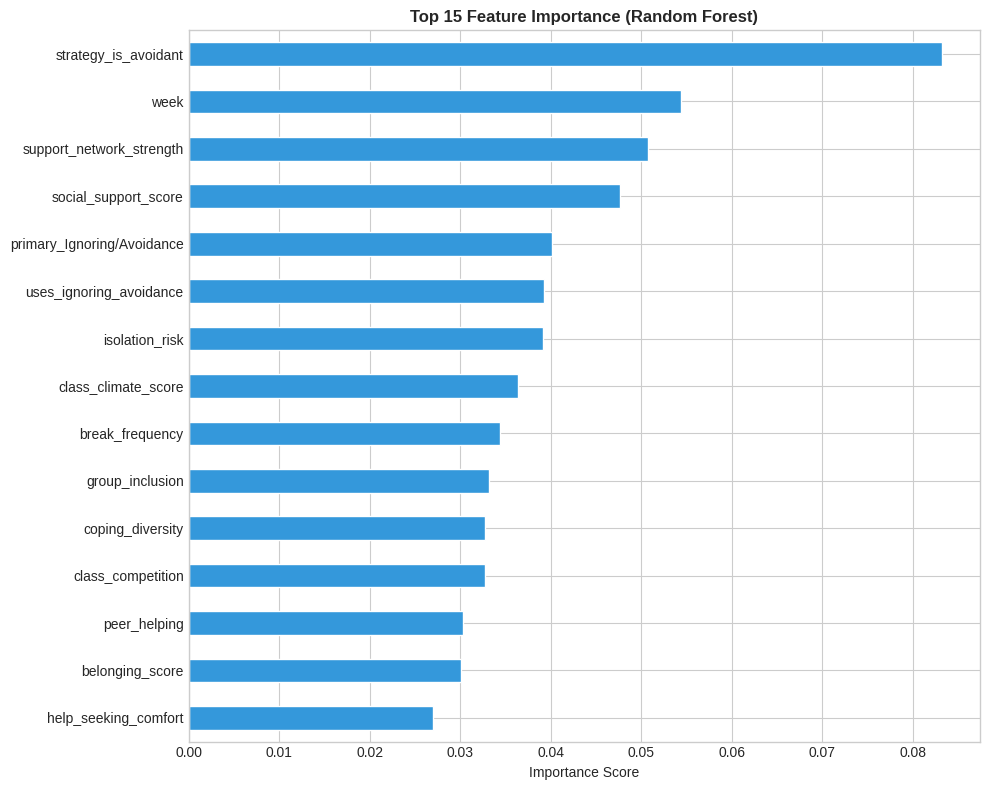

In [16]:
# ============================================================
# EVAL CHART 3: FEATURE IMPORTANCE
# ============================================================
tree_models = {k: v for k, v in all_models.items() if hasattr(v, 'feature_importances_')}
if tree_models:
    best_tree_name = max(tree_models, key=lambda k: all_results[k]['F1_Macro'])
    importances = pd.Series(tree_models[best_tree_name].feature_importances_, index=X.columns)
    top_15 = importances.sort_values(ascending=True).tail(15)

    fig, ax = plt.subplots(figsize=(10, 8))
    top_15.plot(kind='barh', color='#3498db', edgecolor='white', ax=ax)
    ax.set_title(f'Top 15 Feature Importance ({best_tree_name})', fontweight='bold')
    ax.set_xlabel('Importance Score')
    plt.tight_layout()
    plt.savefig('c5_chart7_feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()


Running 5-fold Cross-Validation...
  Random Forest: 0.4834 (+/- 0.0348)
  XGBoost: 0.4344 (+/- 0.0498)
  LightGBM: 0.4367 (+/- 0.0281)
  SVM: 0.4832 (+/- 0.0302)


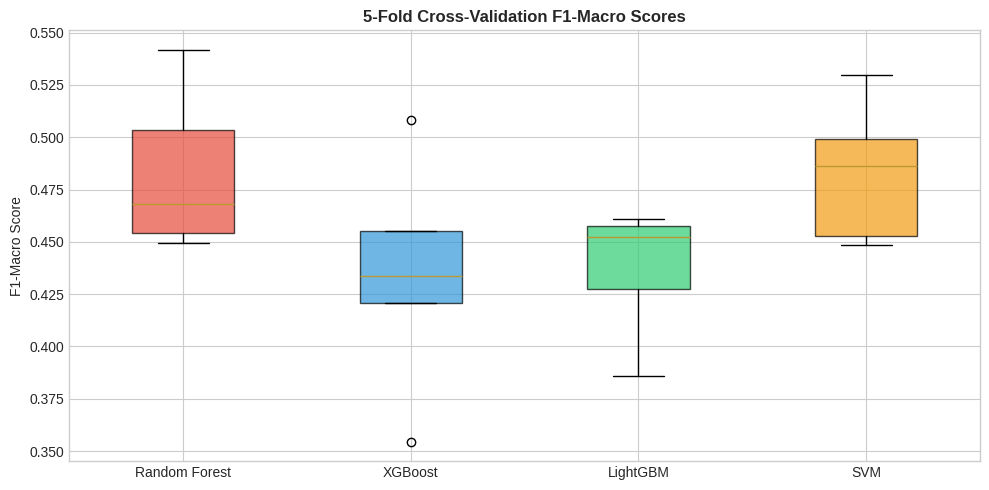

In [17]:
# ============================================================
# EVAL CHART 4: CROSS-VALIDATION BOX PLOT
# ============================================================
print("\nRunning 5-fold Cross-Validation...")
cv_scores = {}
for name, model in all_models.items():
    X_cv = X_train_svm if name == 'SVM' else X_train
    scores = cross_val_score(model, X_cv, y_train, cv=5, scoring='f1_macro', n_jobs=-1)
    cv_scores[name] = scores
    print(f"  {name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

fig, ax = plt.subplots(figsize=(10, 5))
bp = ax.boxplot([cv_scores[n] for n in cv_scores], labels=list(cv_scores.keys()), patch_artist=True)
for patch, color in zip(bp['boxes'], colors_bar[:len(bp['boxes'])]):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax.set_title('5-Fold Cross-Validation F1-Macro Scores', fontweight='bold')
ax.set_ylabel('F1-Macro Score')
plt.tight_layout()
plt.savefig('c5_chart8_cv_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

#### Section 7: Personalized Coping Strategy Recommendation


SECTION 7: PERSONALIZED RECOMMENDATION PIPELINE
Using best model: SVM

--- Personalized Recommendations for 5 Sample Students ---

  Student S168 | Loneliness: 3 | Current Strategy: Sleeping
  Top 3 Recommendations:
    1. Music/Relaxation (score: 2.00)
    2. Talking to someone (score: 2.00)
    3. Exercise/Sports (score: 2.00)

  Student S010 | Loneliness: 1 | Current Strategy: Journaling
  Top 3 Recommendations:
    1. Music/Relaxation (score: 2.00)
    2. Talking to someone (score: 2.00)
    3. Exercise/Sports (score: 2.00)

  Student S192 | Loneliness: 3 | Current Strategy: Sleeping
  Top 3 Recommendations:
    1. Music/Relaxation (score: 2.00)
    2. Talking to someone (score: 2.00)
    3. Exercise/Sports (score: 2.00)

  Student S015 | Loneliness: 3 | Current Strategy: Talking to someone
  Top 3 Recommendations:
    1. Music/Relaxation (score: 2.00)
    2. Talking to someone (score: 2.00)
    3. Exercise/Sports (score: 2.00)

  Student S112 | Loneliness: 2 | Current Strategy: J

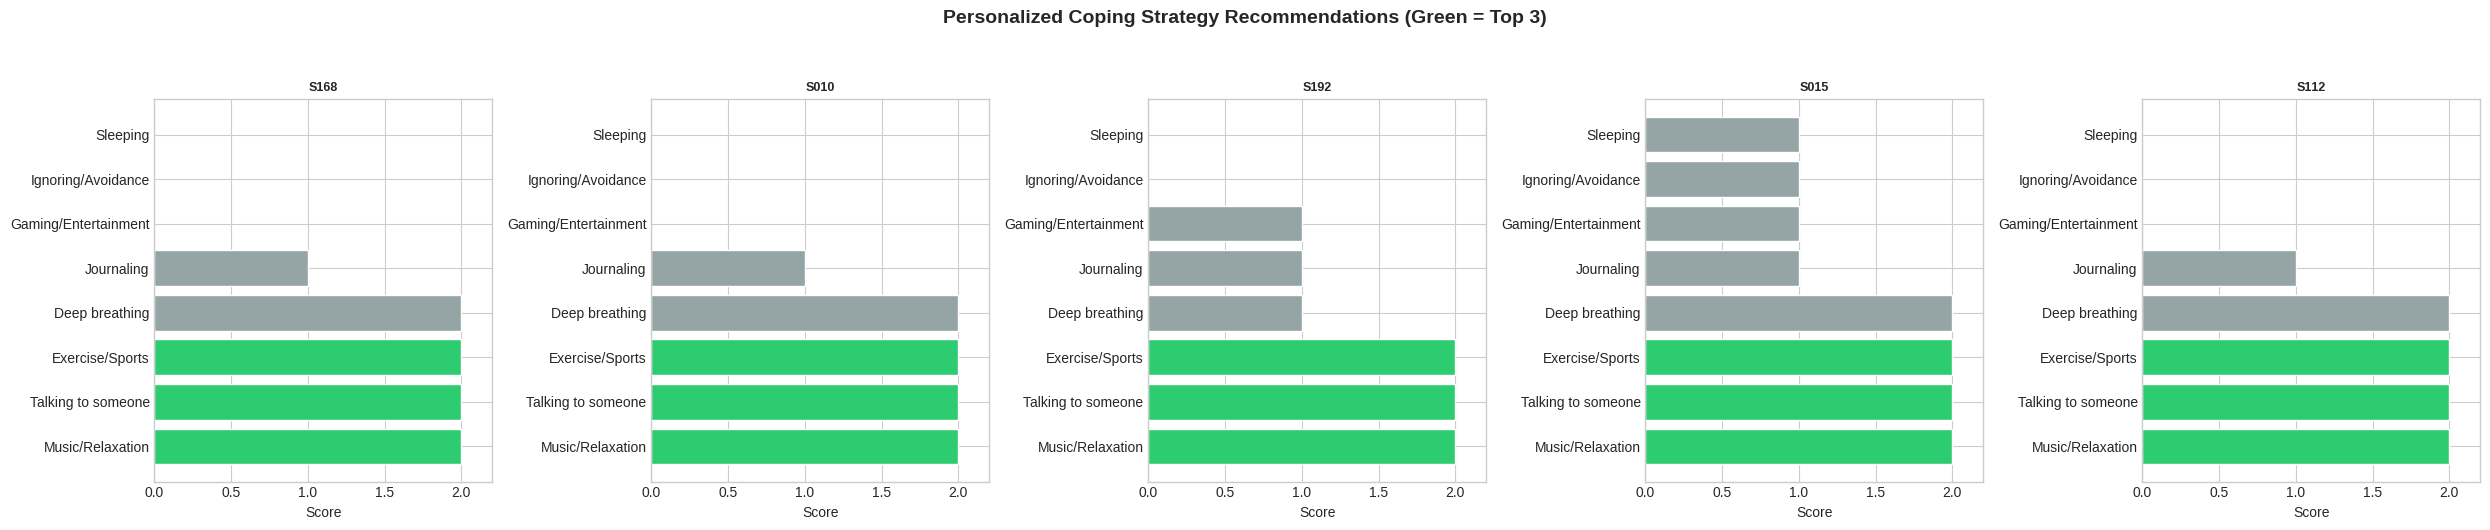

In [18]:
# ============================================================
# RECOMMENDATION PIPELINE
# ============================================================
print("\n" + "=" * 60)
print("SECTION 7: PERSONALIZED RECOMMENDATION PIPELINE")
print("=" * 60)

# Use the best model to recommend strategies
best_name = results_df['F1_Macro'].idxmax()
best_model = all_models[best_name]
print(f"Using best model: {best_name}")

# Strategies to evaluate
ALL_STRATEGIES = ['Music/Relaxation', 'Talking to someone', 'Exercise/Sports',
                  'Deep breathing', 'Journaling', 'Gaming/Entertainment',
                  'Ignoring/Avoidance', 'Sleeping']

def recommend_for_student(student_row, model, feature_cols, mlb_classes):
    """
    For a given student, predict effectiveness of each possible coping strategy.
    Returns ranked recommendations.
    """
    recommendations = []

    for strategy in ALL_STRATEGIES:
        # Create a modified feature vector with this strategy as primary
        test_row = student_row.copy()

        # Update primary strategy columns
        for col in test_row.index:
            if col.startswith('primary_'):
                test_row[col] = 0
        primary_col = f'primary_{strategy}'
        if primary_col in test_row.index:
            test_row[primary_col] = 1

        # Update active/avoidant flags
        active_strats = ['Exercise/Sports', 'Talking to someone', 'Deep breathing']
        avoidant_strats = ['Ignoring/Avoidance', 'Sleeping', 'Gaming/Entertainment']
        test_row['strategy_is_active'] = 1 if strategy in active_strats else 0
        test_row['strategy_is_avoidant'] = 1 if strategy in avoidant_strats else 0

        # Predict
        if best_name == 'SVM':
            features = scaler.transform(test_row.values.reshape(1, -1))
        else:
            features = test_row.values.reshape(1, -1)

        if hasattr(model, 'predict_proba'):
            proba = model.predict_proba(features)[0]
            # Weighted score: 0*p0 + 1*p1 + 2*p2
            score = proba[0] * 0 + proba[1] * 1 + proba[2] * 2
        else:
            pred = model.predict(features)[0]
            score = pred

        recommendations.append({'Strategy': strategy, 'Predicted_Score': score})

    return pd.DataFrame(recommendations).sort_values('Predicted_Score', ascending=False)

# --- Demo: Recommend for 5 sample students ---
print("\n--- Personalized Recommendations for 5 Sample Students ---")

raw_df = pd.read_csv('c3_intervention_dataset.csv')
sample_indices = np.random.choice(X_test.index, 5, replace=False)

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for i, idx in enumerate(sample_indices):
    sid = raw_df.loc[idx, 'student_id']
    risk_label = 'HIGH' if raw_df.loc[idx, 'loneliness_score'] >= 4 else ('MEDIUM' if raw_df.loc[idx, 'loneliness_score'] >= 3 else 'LOW')

    recs = recommend_for_student(X_test.loc[idx], best_model, X.columns, mlb.classes_)

    print(f"\n  Student {sid} | Loneliness: {raw_df.loc[idx, 'loneliness_score']} | "
          f"Current Strategy: {raw_df.loc[idx, 'coping_primary_strategy']}")
    print(f"  Top 3 Recommendations:")
    for j, (_, r) in enumerate(recs.head(3).iterrows()):
        print(f"    {j+1}. {r['Strategy']} (score: {r['Predicted_Score']:.2f})")

    # Plot
    colors_rec = ['#2ecc71' if j < 3 else '#95a5a6' for j in range(len(recs))]
    axes[i].barh(recs['Strategy'], recs['Predicted_Score'], color=colors_rec, edgecolor='white')
    axes[i].set_title(f'{sid}', fontweight='bold', fontsize=9)
    axes[i].set_xlabel('Score')
    axes[i].set_xlim(0, 2.2)

fig.suptitle('Personalized Coping Strategy Recommendations (Green = Top 3)',
             fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('c5_chart9_recommendations.png', dpi=150, bbox_inches='tight')
plt.show()

#### Section 8: Export & Summary

In [19]:
print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)
print(results_df.round(4).to_string())
print(f"\n*** BEST MODEL: {best_name} ***")
for metric, val in all_results[best_name].items():
    print(f"    {metric}: {val:.4f}")

# Save
joblib.dump(all_models[best_name], 'best_coping_model.pkl')
results_df.to_csv('coping_model_results.csv')
print(f"\nModel saved: best_coping_model.pkl")
print(f"Results saved: coping_model_results.csv")

print("\n" + "=" * 60)
print("COMPLETE: Coping Recommendation Model built!")
print("=" * 60)


FINAL SUMMARY
               Accuracy  F1_Macro  F1_Weighted   Kappa     MCC
Random Forest    0.5347    0.4786       0.5244  0.2486  0.2553
XGBoost          0.4950    0.4134       0.4677  0.1435  0.1477
LightGBM         0.4901    0.4331       0.4703  0.1383  0.1411
SVM              0.5347    0.5011       0.5301  0.2809  0.2929

*** BEST MODEL: SVM ***
    Accuracy: 0.5347
    F1_Macro: 0.5011
    F1_Weighted: 0.5301
    Kappa: 0.2809
    MCC: 0.2929

Model saved: best_coping_model.pkl
Results saved: coping_model_results.csv

COMPLETE: Coping Recommendation Model built!
